THE SILENT BREAKDOWN
An Explainable Machine Learning Approach to Industrial Failure Prediction

Objective: To analyze industrial machine operating conditions, identify factors associated with machine failure, and compare machine learning models for predicting rare failures.

Dataset: AI4I 2020 Predictive Maintenance Dataset, UCI Machine Learning Repository.

Research question: Can engineered sensor features and cost-sensitive machine learning improve the detection of rare industrial machine failures?

In [ ]:

# THE SILENT BREAKDOWN
# Phase 1: Dataset Loading

!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Download official UCI dataset
dataset = fetch_ucirepo(id=601)

# Combine input features and target variables
X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:

# Basic dataset inspection

print("DATASET DIMENSIONS")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nDESCRIPTIVE STATISTICS")
display(df.describe(include="all").T)


DATASET DIMENSIONS
Rows: 10000
Columns: 12

COLUMN NAMES
['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type                 10000 non-null  object 
 1   Air temperature      10000 non-null  float64
 2   Process temperature  10000 non-null  float64
 3   Rotational speed     10000 non-null  int64  
 4   Torque               10000 non-null  float64
 5   Tool wear            10000 non-null  int64  
 6   Machine failure      10000 non-null  int64  
 7   TWF                  10000 non-null  int64  
 8   HDF                  10000 non-null  int64  
 9   PWF                  10000 non-null  int64  
 10  OSF                  10000 non-null  int64  
 11  

,Missing Count
Type,0
Air temperature,0
Process temperature,0
Rotational speed,0
Torque,0
Tool wear,0
Machine failure,0
TWF,0
HDF,0
PWF,0



DUPLICATE ROWS
0

DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature,10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature,10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed,10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque,10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear,10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,NaN,NaN,NaN,0.0115,0.106625,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,NaN,NaN,NaN,0.0095,0.097009,0.0,0.0,0.0,0.0,1.0


Failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


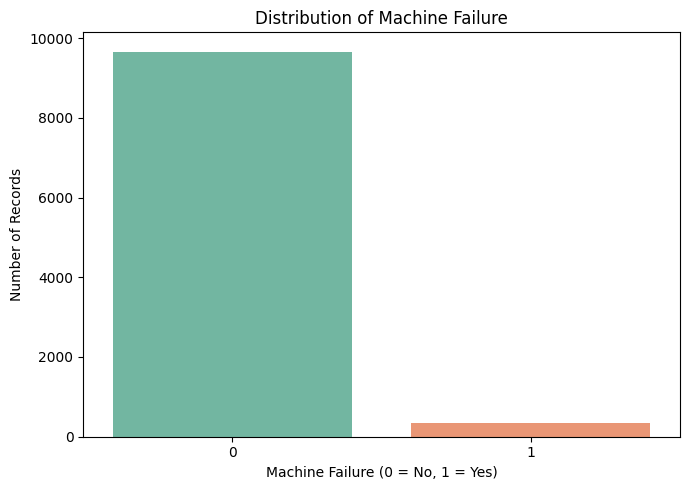

In [ ]:

# Target distribution

target = "Machine failure"

print("Failure counts:")
print(df[target].value_counts())

print("\nFailure percentages:")
print(
    (df[target].value_counts(normalize=True) * 100).round(2)
)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target, hue=target,
              palette="Set2", legend=False)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


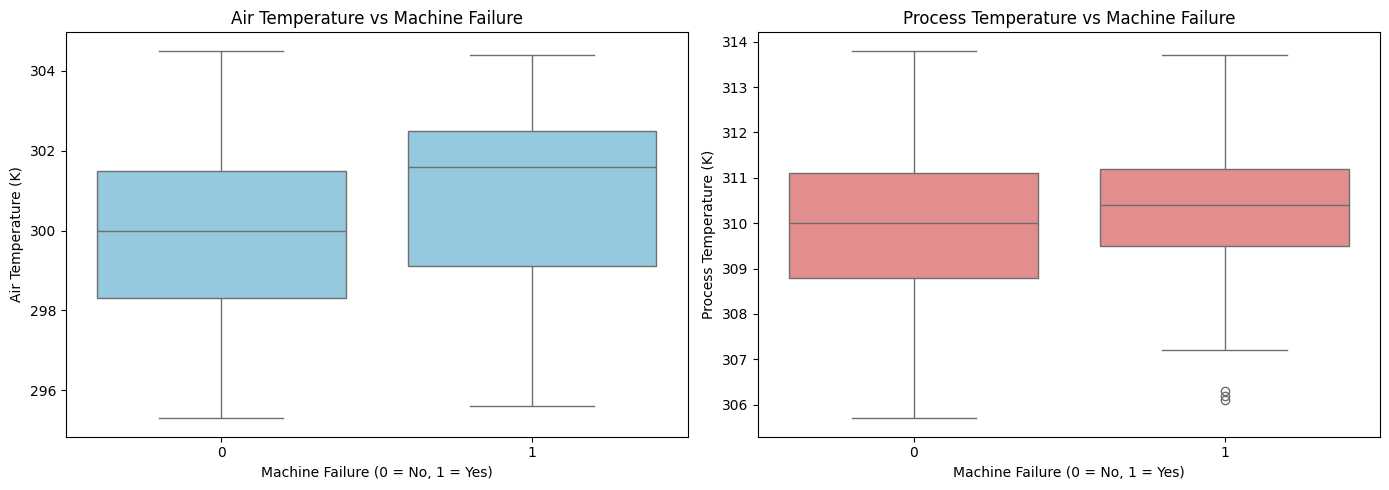

Air temperature              Process temperature             
                           mean median   std                mean median   std
Machine failure                                                              
0                        299.97  300.0  1.99              310.00  310.0  1.49
1                        300.89  301.6  2.07              310.29  310.4  1.36

In [ ]:

# PHASE 2: EXPLORATORY DATA ANALYSIS
# EDA 1: Temperature distribution by machine failure

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Air temperature",
    ax=axes[0],
    color="skyblue"
)

axes[0].set_title("Air Temperature vs Machine Failure")
axes[0].set_xlabel("Machine Failure (0 = No, 1 = Yes)")
axes[0].set_ylabel("Air Temperature (K)")

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Process temperature",
    ax=axes[1],
    color="lightcoral"
)

axes[1].set_title("Process Temperature vs Machine Failure")
axes[1].set_xlabel("Machine Failure (0 = No, 1 = Yes)")
axes[1].set_ylabel("Process Temperature (K)")

plt.tight_layout()
plt.show()

# Group-wise summary statistics
temperature_summary = df.groupby("Machine failure")[
    ["Air temperature", "Process temperature"]
].agg(["mean", "median", "std"])

display(temperature_summary.round(2))


### EDA 1: Temperature Analysis — Interpretation

The temperature analysis compares operating conditions between failed and non-failed machines.

The mean air temperature was 300.89 K for failed machines and 299.97 K for non-failed machines, representing a difference of approximately 0.92 K.

Similarly, the mean process temperature was 310.29 K for failed machines and 310.00 K for non-failed machines, indicating a smaller difference of approximately 0.29 K.

The boxplots show substantial overlap between the two classes. Therefore, temperature measurements alone may not be sufficient to accurately predict machine failures.

These observations suggest an association between temperature and machine failure, but further statistical testing and multivariable modelling are necessary to assess the relationships.

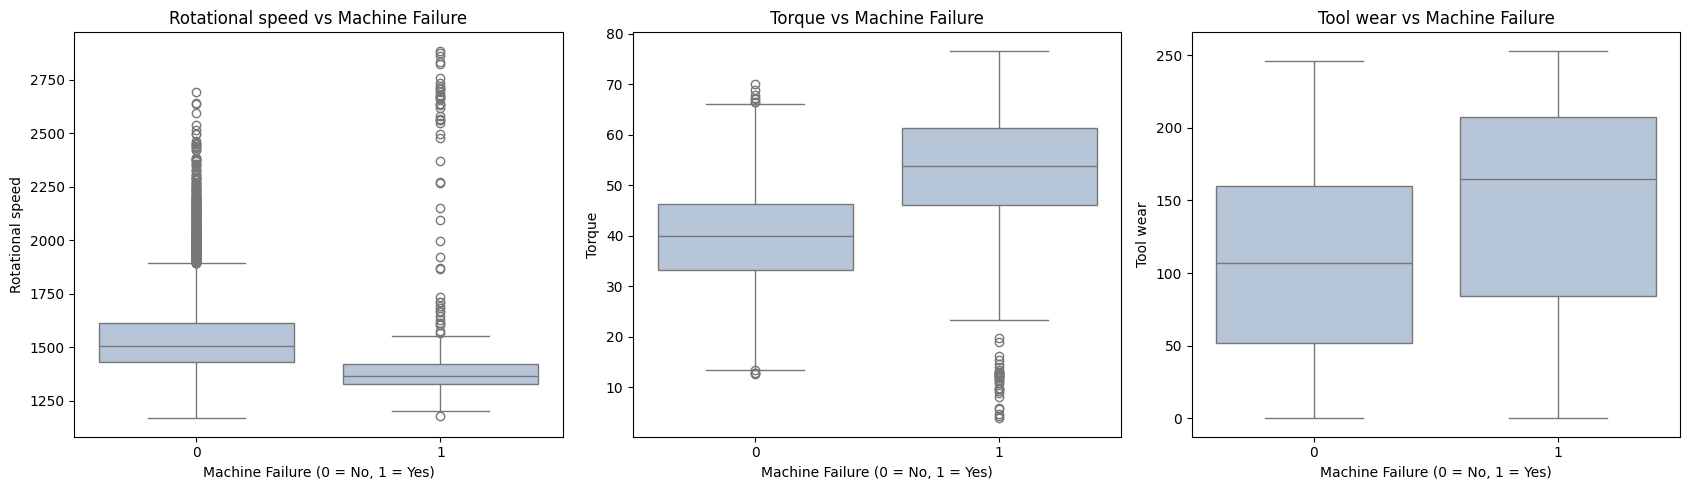

Rotational speed                 Torque                \
                            mean  median     std   mean median    std   
Machine failure                                                         
0                        1540.26  1507.0  167.39  39.63   39.9   9.47   
1                        1496.49  1365.0  384.94  50.17   53.7  16.37   

                Tool wear                
                     mean median    std  
Machine failure                          
0                  106.69  107.0  62.95  
1                  143.78  165.0  72.76

In [ ]:

# PHASE 2: EDA 2
# Mechanical operating conditions vs machine failure

features = [
    "Rotational speed",
    "Torque",
    "Tool wear"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=ax,
        color="lightsteelblue"
    )

    ax.set_title(f"{feature} vs Machine Failure")
    ax.set_xlabel("Machine Failure (0 = No, 1 = Yes)")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

# Compare statistics between failed and non-failed machines
mechanical_summary = df.groupby("Machine failure")[
    features
].agg(["mean", "median", "std"])

display(mechanical_summary.round(2))


### EDA 2: Mechanical Operating Conditions — Interpretation

The analysis compares rotational speed, torque, and tool wear between failed and non-failed machines.

Failed machines recorded a lower median rotational speed (1,365 rpm) than non-failed machines (1,507 rpm). However, rotational speed varied considerably among failed machines, including observations at unusually high speeds.

Torque showed a noticeable difference between the groups. Failed machines had a mean torque of 50.17 Nm, compared with 39.63 Nm for non-failed machines, suggesting an association between higher mechanical load and machine failure.

Tool wear was also higher among failed machines, with a median of 165 minutes compared with 107 minutes for non-failed machines.

Overall, torque and tool wear show substantial differences between the two groups. Further analysis is needed to determine how these measurements interact with rotational speed and contribute to failure prediction.

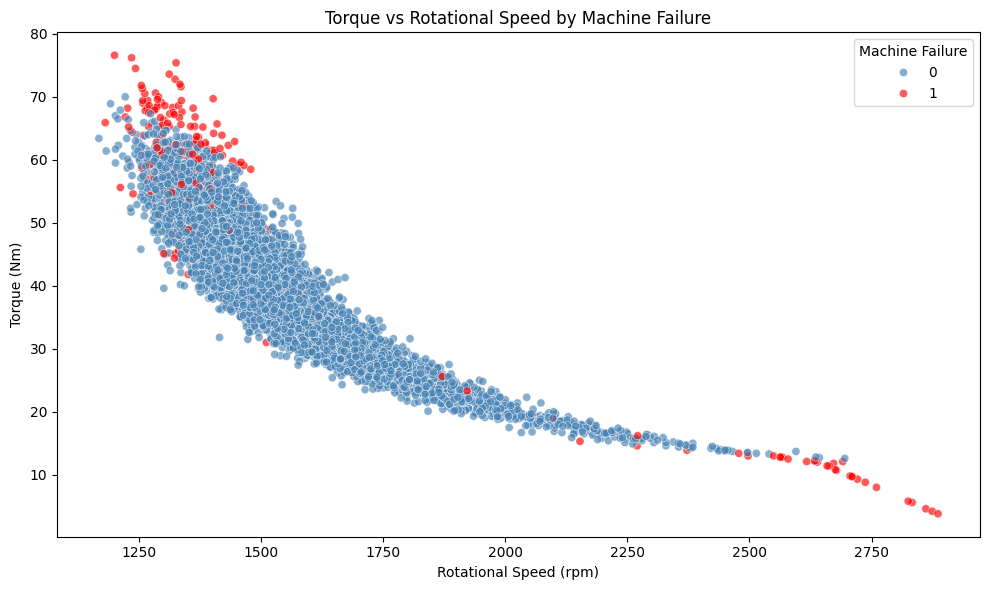

Pearson correlation between rotational speed and torque: -0.8750


In [ ]:

# PHASE 2: EDA 3
# Relationship between torque and rotational speed

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Rotational speed",
    y="Torque",
    hue="Machine failure",
    palette={0: "steelblue", 1: "red"},
    alpha=0.65,
    s=35
)

plt.title("Torque vs Rotational Speed by Machine Failure")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend(title="Machine Failure")
plt.tight_layout()
plt.show()

# Pearson correlation between torque and rotational speed
correlation = df[
    ["Rotational speed", "Torque"]
].corr().iloc[0, 1]

print(
    "Pearson correlation between rotational speed "
    f"and torque: {correlation:.4f}"
)


### EDA 3: Relationship Between Torque and Rotational Speed

The scatterplot reveals a strong negative relationship between rotational speed and torque, with a Pearson correlation coefficient of **−0.8750**.

As rotational speed increases, torque generally decreases.

Failure observations are particularly noticeable in two regions: low rotational speed combined with high torque, and extremely high rotational speed combined with low torque.

These patterns suggest that machine failure may be associated with unusual combinations of mechanical operating conditions.

The findings motivate the creation of an engineered mechanical-power feature that combines torque and rotational speed. Further analysis is required to determine whether this feature improves failure prediction.

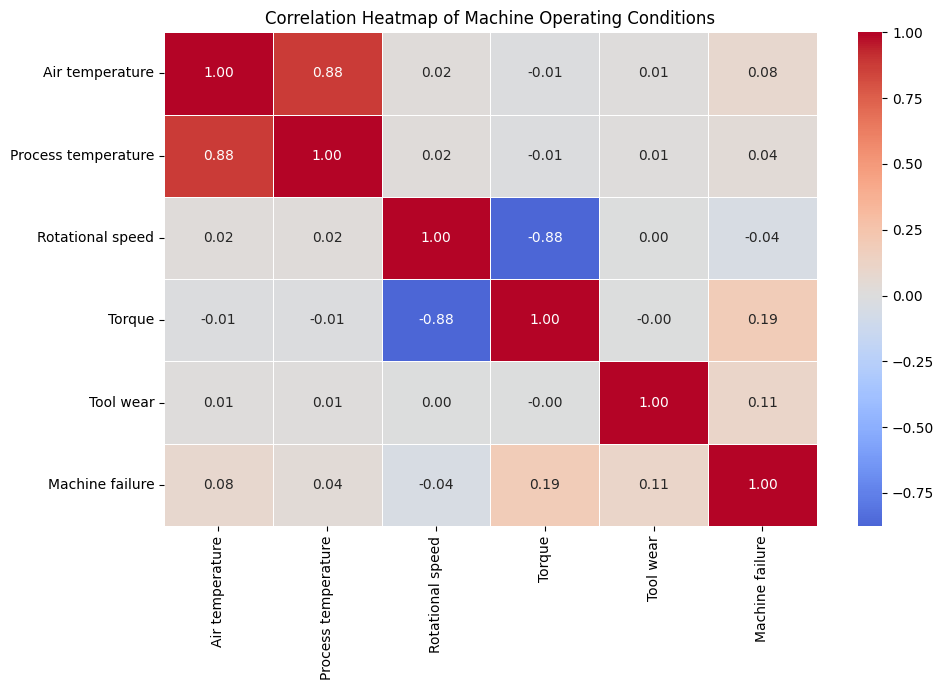

Correlation with Machine Failure:


,Machine failure
Torque,0.1913
Tool wear,0.1054
Air temperature,0.0826
Process temperature,0.0359
Rotational speed,-0.0442


In [ ]:

# PHASE 2: EDA 4
# Correlation heatmap of sensor measurements

sensor_columns = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

# Include the target for exploratory association analysis
correlation_columns = sensor_columns + ["Machine failure"]

corr_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Machine Operating Conditions")
plt.tight_layout()
plt.show()

print("Correlation with Machine Failure:")
display(
    corr_matrix["Machine failure"]
    .drop("Machine failure")
    .sort_values(ascending=False)
    .round(4)
)


### EDA 4: Correlation Analysis — Interpretation

The correlation heatmap was used to investigate linear relationships among machine operating measurements and the machine-failure target.

Air temperature and process temperature showed a strong positive correlation of approximately **0.88**, indicating that higher ambient temperatures generally correspond to higher process temperatures.

Rotational speed and torque demonstrated a strong negative correlation of approximately **−0.88**, suggesting that higher rotational speeds are generally associated with lower torque values.

Among the numerical sensor measurements, torque exhibited the strongest positive correlation with machine failure (**0.19**), followed by tool wear (**0.11**).

However, all individual sensor correlations with machine failure were relatively weak. This suggests that machine failures may depend on nonlinear relationships and interactions among multiple operating conditions rather than any single measurement.

These findings motivate feature engineering and the comparison of linear and nonlinear classification models.

In [ ]:

# PHASE 3: FEATURE ENGINEERING

# Create a separate dataset to preserve the original data
df_engineered = df.copy()

# Feature 1: Temperature difference
df_engineered["Temperature difference"] = (
    df_engineered["Process temperature"]
    - df_engineered["Air temperature"]
)

# Feature 2: Rotational mechanical power (watts)
df_engineered["Mechanical power"] = (
    df_engineered["Torque"]
    * 2 * np.pi
    * df_engineered["Rotational speed"] / 60
)

# Feature 3: Wear-load interaction
df_engineered["Wear-load interaction"] = (
    df_engineered["Tool wear"]
    * df_engineered["Torque"]
)

engineered_features = [
    "Temperature difference",
    "Mechanical power",
    "Wear-load interaction"
]

print("Engineered features created successfully!")

display(df_engineered[engineered_features].head())

print("\nDescriptive statistics:")
display(
    df_engineered[engineered_features]
    .describe()
    .round(2)
)

print("\nCorrelation with machine failure:")
display(
    df_engineered[
        engineered_features + ["Machine failure"]
    ]
    .corr()["Machine failure"]
    .drop("Machine failure")
    .sort_values(ascending=False)
    .round(4)
)


Engineered features created successfully!


,Temperature difference,Mechanical power,Wear-load interaction
0,10.5,6951.590560,0.0
1,10.5,6826.722724,138.9
2,10.4,7749.387543,247.0
3,10.4,5927.504659,276.5
4,10.5,5897.816608,360.0



Descriptive statistics:


,Temperature difference,Mechanical power,Wear-load interaction
count,10000.0,10000.00,10000.00
mean,10.0,6279.74,4314.66
std,1.0,1067.42,2826.57
min,7.6,1148.44,0.00
25%,9.3,5561.18,1963.65
50%,9.8,6271.03,4012.95
75%,11.0,7003.00,6279.00
max,12.1,10469.92,16497.00



Correlation with machine failure:


,Machine failure
Wear-load interaction,0.1904
Mechanical power,0.1760
Temperature difference,-0.1117


## Phase 4: Statistical Hypothesis Testing

### Objective

To determine whether selected machine operating measurements differ significantly between failed and non-failed machines.

### Methodology

Welch's independent-samples t-test is used to compare group means without assuming equal variances. Cohen's d is calculated to quantify standardized effect sizes.

The significance level is set to 0.05, and Holm's correction is applied to account for multiple hypothesis tests.

These tests investigate associations within the synthetic dataset and do not establish causal relationships.

In [ ]:

# PHASE 4: STATISTICAL HYPOTHESIS TESTING
# Welch's t-test + Cohen's d effect size

from scipy.stats import ttest_ind
import pandas as pd
import numpy as np

test_features = [
    "Torque",
    "Tool wear",
    "Air temperature"
]

results = []

for feature in test_features:

    healthy = df.loc[
        df["Machine failure"] == 0, feature
    ]

    failed = df.loc[
        df["Machine failure"] == 1, feature
    ]

    # Welch's t-test: unequal variances
    t_stat, p_value = ttest_ind(
        failed, healthy, equal_var=False
    )

    # Cohen's d: standardized mean difference
    n1, n0 = len(failed), len(healthy)
    s1, s0 = failed.std(ddof=1), healthy.std(ddof=1)

    pooled_sd = np.sqrt(
        ((n1 - 1) * s1**2 + (n0 - 1) * s0**2)
        / (n1 + n0 - 2)
    )

    cohens_d = (
        (failed.mean() - healthy.mean()) / pooled_sd
    )

    results.append({
        "Feature": feature,
        "Mean (No failure)": healthy.mean(),
        "Mean (Failure)": failed.mean(),
        "t-statistic": t_stat,
        "p-value": p_value,
        "Cohen's d": cohens_d
    })

results_df = pd.DataFrame(results)

# Correct for testing multiple features
from statsmodels.stats.multitest import multipletests

results_df["Adjusted p-value"] = multipletests(
    results_df["p-value"],
    method="holm"
)[1]

display(results_df.round(5))

print("\nSIGNIFICANCE (Holm-adjusted p < 0.05):")
for _, row in results_df.iterrows():
    status = (
        "Significant"
        if row["Adjusted p-value"] < 0.05
        else "Not significant"
    )
    print(f"{row['Feature']}: {status}")

    # Display exact p-values in scientific notation
print("\nP-VALUES IN SCIENTIFIC NOTATION:")

print(
    results_df[
        ["Feature", "p-value", "Adjusted p-value"]
    ].to_string(index=False, float_format=lambda x: f"{x:.3e}")
)


,Feature,Mean (No failure),Mean (Failure),t-statistic,p-value,Cohen's d,Adjusted p-value
0,Torque,39.62966,50.16814,11.78081,0.0,1.07697,0.0
1,Tool wear,106.69372,143.78171,9.26429,0.0,0.58589,0.0
2,Air temperature,299.97400,300.88643,7.98170,0.0,0.45770,0.0



SIGNIFICANCE (Holm-adjusted p < 0.05):
Torque: Significant
Tool wear: Significant
Air temperature: Significant

P-VALUES IN SCIENTIFIC NOTATION:
        Feature   p-value  Adjusted p-value
         Torque 3.636e-27         1.091e-26
      Tool wear 1.906e-18         3.812e-18
Air temperature 1.951e-14         1.951e-14


### Phase 4: Statistical Hypothesis Testing — Results and Interpretation

Welch's independent-samples t-tests were conducted to compare torque, tool wear, and air temperature between failed and non-failed machines. Holm's correction was applied to account for multiple comparisons, using a significance level of 0.05.

All three features showed statistically significant differences between the two groups after adjustment.

**Torque:** Failed machines had a higher mean torque (50.17 Nm) than non-failed machines (39.63 Nm). The test produced a t-statistic of 11.78 and Cohen's d of 1.08, indicating a large standardized difference.

**Tool wear:** Failed machines had a higher mean tool wear (143.78 minutes) than non-failed machines (106.69 minutes). The t-statistic was 9.26, with Cohen's d of 0.59, indicating a moderate standardized difference.

**Air temperature:** Failed machines had a higher mean air temperature (300.89 K) than non-failed machines (299.97 K). The t-statistic was 7.98, with Cohen's d of 0.46, indicating a smaller standardized difference.

**Conclusion:** The results provide evidence of differences in selected operating measurements between failed and non-failed machines in the synthetic AI4I dataset. Torque exhibited the largest standardized difference among the three tested features. These associations motivate further investigation using multivariable machine learning models.

Statistical significance does not imply causation or guarantee predictive usefulness.

## Phase 5: Principal Component Analysis (PCA)

### Objective

To investigate dimensionality reduction and visualize machine operating conditions in a lower-dimensional feature space.

### Methodology

The dataset is divided into stratified training and testing subsets to preserve the proportion of machine failures.

Numerical features are standardized using statistics calculated from the training data only. PCA is then fitted to the standardized training features.

Explained variance ratios are examined to determine how much information is retained by the principal components.

PCA is used as an exploratory dimensionality-reduction technique, and its predictive usefulness will be evaluated separately.

In [ ]:

# PHASE 5: PCA
# Leakage-safe training/test split and dimensionality reduction

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Use numerical sensor features only for initial PCA
pca_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear",
    "Temperature difference",
    "Mechanical power",
    "Wear-load interaction"
]

X = df_engineered[pca_features].copy()
y = df_engineered["Machine failure"].copy()

# Stratified split maintains failure proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit scaler ONLY on training data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit PCA ONLY on training data
pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_summary = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nFailure distribution in training data:")
print(y_train.value_counts())

print("\nFailure distribution in testing data:")
print(y_test.value_counts())

display(pca_summary.round(2))


Training shape: (8000, 8)
Testing shape: (2000, 8)

Failure distribution in training data:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Failure distribution in testing data:
Machine failure
0    1932
1      68
Name: count, dtype: int64


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,37.62,37.62
1,PC2,28.28,65.91
2,PC3,21.70,87.60
3,PC4,9.22,96.82
4,PC5,2.68,99.50
5,PC6,0.35,99.85
6,PC7,0.15,100.00
7,PC8,0.00,100.00


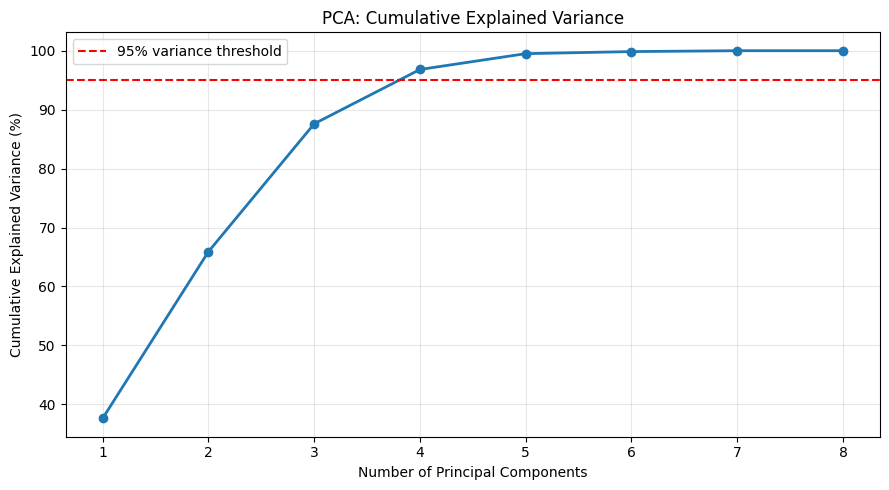

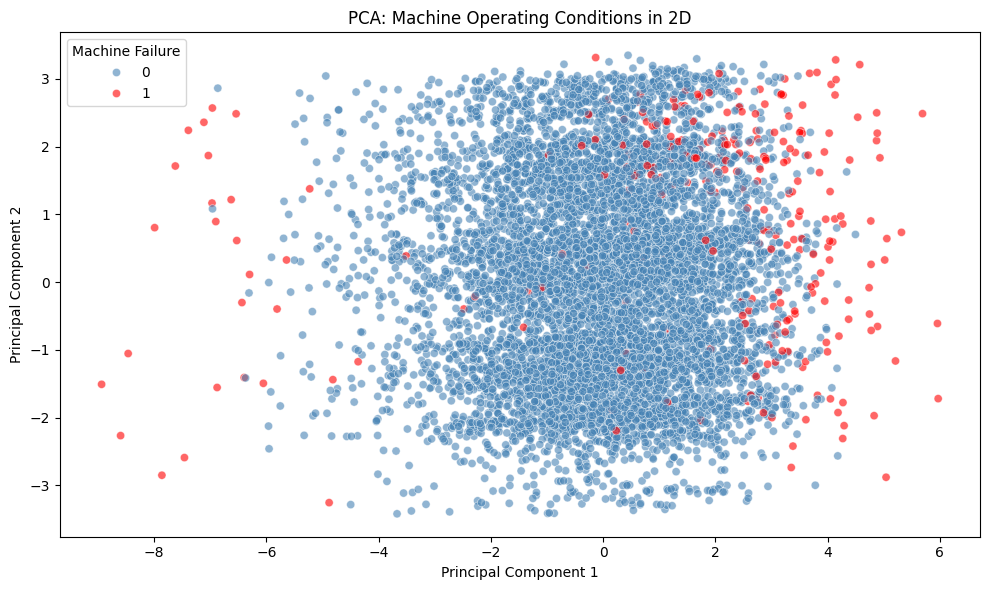

In [ ]:

# PHASE 5: PCA VISUALIZATION

import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Explained variance
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o",
    linewidth=2
)

plt.axhline(
    y=95,
    color="red",
    linestyle="--",
    label="95% variance threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA: Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 2: PCA scatterplot using TRAINING data only
pca_plot_df = pd.DataFrame({
    "PC1": X_train_pca[:, 0],
    "PC2": X_train_pca[:, 1],
    "Machine failure": y_train.to_numpy()
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Machine failure",
    palette={0: "steelblue", 1: "red"},
    alpha=0.6,
    s=35
)

plt.title("PCA: Machine Operating Conditions in 2D")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Machine Failure")
plt.tight_layout()
plt.show()


### Phase 5: PCA — Results and Interpretation

Principal Component Analysis (PCA) was performed on eight standardized numerical features to investigate dimensionality reduction and visualize machine operating conditions.

The first two principal components explained approximately **65.91%** of the total variance, while the first four explained **96.82%**, exceeding the selected 95% cumulative variance threshold.

The two-dimensional PCA scatterplot revealed substantial overlap between failed and non-failed machines. Although some failure observations appeared toward the outer regions of the distribution, the first two principal components did not provide clear separation between the two classes.

This indicates that the directions capturing the greatest variation in the operating measurements do not necessarily distinguish machine failures effectively.

**Conclusion:** Four principal components offer a reasonable option for dimensionality reduction, but their usefulness for failure prediction must be evaluated separately. The overlap observed in the two-dimensional visualization motivates the use of supervised classification models capable of learning more complex relationships.

## Phase 6: Machine Learning — Machine Failure Classification

### Objective

To develop and compare classification models for identifying machine failures using operating measurements from the AI4I 2020 Predictive Maintenance dataset.

### Models

1. **Dummy Classifier:** Establishes a majority-class baseline.
2. **Logistic Regression:** Provides an interpretable linear classification model.
3. **Random Forest:** Captures nonlinear relationships and interactions among machine measurements.

### Methodology

The dataset is divided into stratified training and testing subsets (80:20). The training data is used for model development, while the test data is reserved for final evaluation.

Categorical machine type is one-hot encoded, and numerical features are standardized for logistic regression. Preprocessing is fitted only on training data to prevent data leakage.

The failure-mode labels (TWF, HDF, PWF, OSF and RNF) are excluded from the predictors because they describe failure outcomes rather than ordinary operating measurements.

Because only 3.39% of observations represent failures, model performance will be assessed using precision, recall, F1-score, PR-AUC and confusion matrices rather than accuracy alone.

In [ ]:

# PHASE 6A: MACHINE LEARNING MODEL TRAINING
# Baseline, Logistic Regression, and Random Forest

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Define predictors and target
# Exclude failure-mode labels and identifiers.
# Include original measurements and engineered features.

numeric_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear",
    "Temperature difference",
    "Mechanical power",
    "Wear-load interaction"
]

categorical_features = ["Type"]

feature_columns = numeric_features + categorical_features

X_ml = df_engineered[feature_columns].copy()
y_ml = df_engineered["Machine failure"].copy()

# 2. Recreate the SAME stratified split as Phase 5
# (same rows, random_state and stratification)

X_train_ml, X_test_ml, y_train_ml, y_test_ml = (
    train_test_split(
        X_ml,
        y_ml,
        test_size=0.20,
        random_state=42,
        stratify=y_ml
    )
)

print("Training records:", len(X_train_ml))
print("Testing records:", len(X_test_ml))
print("Training failures:", y_train_ml.sum())
print("Testing failures:", y_test_ml.sum())

# 3. Preprocessing
# Logistic regression requires scaled numerical features.
# Random forest does not require scaling.

linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# 4. Define three models

models = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": Pipeline([
        ("preprocess", linear_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocess", tree_preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# 5. Five-fold stratified cross-validation
# All preprocessing is fitted within each training fold.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train_ml,
        y_train_ml,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "PR-AUC": scores["test_pr_auc"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print("\n5-FOLD CROSS-VALIDATION RESULTS")
print("(Training data only)")

display(cv_results_df.round(4))


Training records: 8000
Testing records: 2000
Training failures: 271
Testing failures: 68

5-FOLD CROSS-VALIDATION RESULTS
(Training data only)


,Model,Precision,Recall,F1-score,PR-AUC,ROC-AUC
0,Dummy Baseline,0.0000,0.0000,0.0000,0.0339,0.5000
1,Logistic Regression,0.1618,0.8415,0.2713,0.4586,0.9233
2,Random Forest,0.9476,0.8080,0.8720,0.8950,0.9794


### Phase 6A: Model Training — Cross-Validation Results

Three classification models were compared using five-fold stratified cross-validation on the training dataset: a majority-class Dummy Classifier, Logistic Regression, and Random Forest.

The Dummy Classifier obtained zero precision, recall, and F1-score because it predicted only the majority class. Its PR-AUC was approximately 0.0339, reflecting the low prevalence of machine failures.

Logistic Regression achieved a recall of **0.8415**, indicating that it identified a high proportion of failure observations. However, its precision was only **0.1618**, suggesting a substantial number of false-positive predictions at the default decision threshold.

Random Forest achieved a precision of **0.9476**, recall of **0.8080**, F1-score of **0.8720**, and PR-AUC of **0.8950**. It provided the strongest overall balance between identifying failures and limiting false alarms among the evaluated models.

These results suggest that nonlinear models can capture relationships in the operating measurements that are not adequately represented by a linear decision boundary.

**Conclusion:** Random Forest was selected as the leading candidate for final evaluation on the held-out test set. The results are specific to the synthetic AI4I dataset and should not be interpreted as verified performance in real industrial settings.

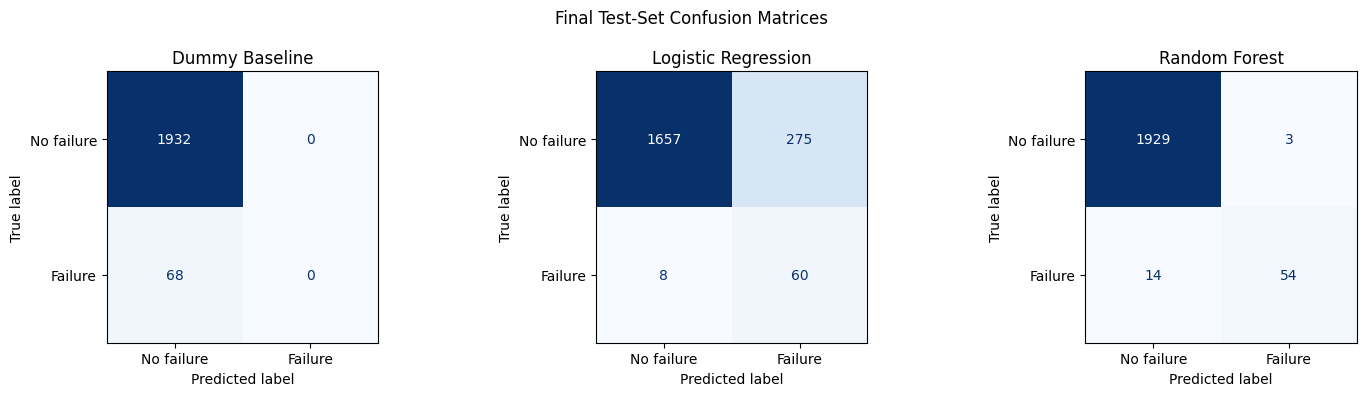


FINAL TEST-SET PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-score,PR-AUC,ROC-AUC
0,Dummy Baseline,0.9660,0.0000,0.0000,0.0000,0.0340,0.5000
1,Logistic Regression,0.8585,0.1791,0.8824,0.2978,0.4297,0.9385
2,Random Forest,0.9915,0.9474,0.7941,0.8640,0.8724,0.9777



RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No failure       0.99      1.00      1.00      1932
     Failure       0.95      0.79      0.86        68

    accuracy                           0.99      2000
   macro avg       0.97      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000



In [ ]:

# PHASE 6B: FINAL TEST-SET EVALUATION

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd

fitted_models = {}
test_results = []

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):

    # Train on the full training set
    fitted_model = clone(model)
    fitted_model.fit(X_train_ml, y_train_ml)

    fitted_models[name] = fitted_model

    # Predict on held-out test set
    y_pred = fitted_model.predict(X_test_ml)
    y_prob = fitted_model.predict_proba(X_test_ml)[:, 1]

    # Calculate metrics
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_ml, y_pred),
        "Precision": precision_score(
            y_test_ml, y_pred, zero_division=0
        ),
        "Recall": recall_score(y_test_ml, y_pred),
        "F1-score": f1_score(y_test_ml, y_pred),
        "PR-AUC": average_precision_score(
            y_test_ml, y_prob
        ),
        "ROC-AUC": roc_auc_score(
            y_test_ml, y_prob
        )
    })

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test_ml,
        y_pred,
        labels=[0, 1],
        display_labels=["No failure", "Failure"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.suptitle("Final Test-Set Confusion Matrices")
plt.tight_layout()
plt.show()

test_results_df = pd.DataFrame(test_results)

print("\nFINAL TEST-SET PERFORMANCE")
display(test_results_df.round(4))

print("\nRANDOM FOREST CLASSIFICATION REPORT")

from sklearn.metrics import classification_report

rf_predictions = fitted_models["Random Forest"].predict(
    X_test_ml
)

print(
    classification_report(
        y_test_ml,
        rf_predictions,
        target_names=["No failure", "Failure"]
    )
)


### Phase 6B: Final Test-Set Evaluation — Results and Interpretation

The three classification models were evaluated on a held-out test dataset containing 2,000 observations, including 68 machine failures and 1,932 non-failures.

**Dummy Classifier:** The majority-class baseline achieved 96.60% accuracy but failed to identify any machine failures. This demonstrates why accuracy alone is inadequate for evaluating highly imbalanced classification problems.

**Logistic Regression:** The model achieved 85.85% accuracy, 17.91% precision, 88.24% recall, and an F1-score of 0.2978. Its confusion matrix showed 60 correctly detected failures, 8 missed failures, and 275 false alarms. Although it achieved the highest failure recall, its low precision indicates a substantial false-positive burden.

**Random Forest:** The model achieved 99.15% accuracy, 94.74% precision, 79.41% recall, and an F1-score of 0.8640. Its PR-AUC was 0.8724. It correctly detected 54 failures, missed 14 failures, and generated only 3 false alarms.

**Model Comparison:** Random Forest provided the strongest overall balance of precision and recall at the evaluated decision threshold. Logistic Regression achieved higher recall but produced substantially more false-positive predictions.

**Conclusion:** The results demonstrate that machine failure observations can be classified effectively within the synthetic AI4I dataset using nonlinear machine learning methods. However, the models should not be considered validated for deployment on real industrial machinery without external evaluation.

The evaluation also highlights the importance of considering both missed failures and false alarms when assessing predictive-maintenance systems.

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
2,Rotational speed,0.2186
3,Torque,0.1949
6,Mechanical power,0.1687
4,Tool wear,0.1329
7,Wear-load interaction,0.1157
5,Temperature difference,0.0793
0,Air temperature,0.0502
1,Process temperature,0.0296
10,Type_M,0.0042
9,Type_L,0.0037


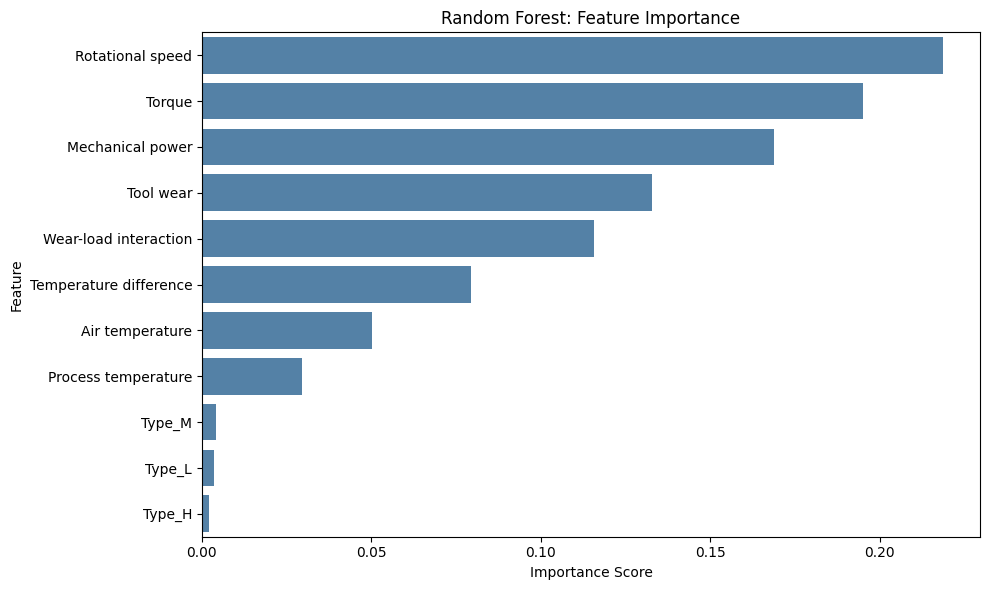

In [ ]:

# PHASE 7A: RANDOM FOREST FEATURE IMPORTANCE

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rf_pipeline = fitted_models["Random Forest"]

# Extract the trained Random Forest and preprocessing step
rf_model = rf_pipeline.named_steps["classifier"]
rf_preprocessor = rf_pipeline.named_steps["preprocess"]

# Get feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Build feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

# Make feature labels easier to read
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(importance_df.round(4))

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Random Forest: Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### Phase 7A: Random Forest Feature Importance — Interpretation

The Random Forest feature importance analysis identified rotational speed (21.86%), torque (19.49%), and engineered mechanical power (16.87%) as the three highest-ranked predictors.

Together, these features account for approximately 58.2% of the model's total impurity-based importance.

Tool wear (13.29%) and the engineered wear-load interaction (11.57%) also contributed substantially, suggesting that operating load and accumulated wear are useful indicators for classifying machine failures in this dataset.

Temperature difference contributed 7.93%, while the individual air and process temperatures received lower importance scores.

The machine-type indicators had relatively low individual importance.

**Key Finding:** Mechanical operating conditions and engineered interaction features were prominent in the Random Forest's predictions.

**Limitation:** Impurity-based feature importance measures how features contribute to the fitted model's decision trees. It does not establish causal relationships, and importance may be distributed among correlated features.

## Phase 7B: Random Forest Error Analysis

### Objective
To investigate false negatives (missed machine failures) and false positives (false alarms), and compare the operating conditions of missed and correctly detected failures.

In [ ]:

# PHASE 7B: RANDOM FOREST ERROR ANALYSIS

import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

# Use the same held-out test set used in Phase 6B
rf_pipeline = fitted_models["Random Forest"]

y_pred_rf = rf_pipeline.predict(X_test_ml)

# Create error analysis table
error_df = X_test_ml.copy().reset_index(drop=True)

error_df["Actual failure"] = (
    y_test_ml.reset_index(drop=True)
)

error_df["Predicted failure"] = y_pred_rf

# Categorize predictions
false_negatives = error_df[
    (error_df["Actual failure"] == 1) &
    (error_df["Predicted failure"] == 0)
]

false_positives = error_df[
    (error_df["Actual failure"] == 0) &
    (error_df["Predicted failure"] == 1)
]

true_positives = error_df[
    (error_df["Actual failure"] == 1) &
    (error_df["Predicted failure"] == 1)
]

print("RANDOM FOREST ERROR ANALYSIS")
print("-" * 45)

print("False negatives (missed failures):",
      len(false_negatives))

print("False positives (false alarms):",
      len(false_positives))

print("True positives (detected failures):",
      len(true_positives))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test_ml, y_pred_rf))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_ml,
    y_pred_rf,
    target_names=["No failure", "Failure"]
))

# Compare missed and detected failures
features_to_compare = [
    "Rotational speed",
    "Torque",
    "Tool wear",
    "Mechanical power",
    "Wear-load interaction",
    "Temperature difference"
]

comparison = pd.DataFrame({
    "Missed failures": false_negatives[
        features_to_compare
    ].mean(),
    "Detected failures": true_positives[
        features_to_compare
    ].mean()
})

print("\nAVERAGE OPERATING CONDITIONS")
display(comparison.round(2))

print("\nEXAMPLES OF MISSED FAILURES")
display(
    false_negatives[
        features_to_compare
    ].head(10).round(2)
)


RANDOM FOREST ERROR ANALYSIS
---------------------------------------------
False negatives (missed failures): 14
False positives (false alarms): 3
True positives (detected failures): 54

CONFUSION MATRIX
[[1929    3]
 [  14   54]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No failure       0.99      1.00      1.00      1932
     Failure       0.95      0.79      0.86        68

    accuracy                           0.99      2000
   macro avg       0.97      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000


AVERAGE OPERATING CONDITIONS


,Missed failures,Detected failures
Rotational speed,1533.21,1465.67
Torque,40.89,52.56
Tool wear,181.79,145.94
Mechanical power,6324.25,7492.67
Wear-load interaction,6937.08,7693.74
Temperature difference,9.84,9.28



EXAMPLES OF MISSED FAILURES


,Rotational speed,Torque,Tool wear,Mechanical power,Wear-load interaction,Temperature difference
97,1465,59.1,91,9066.79,5378.1,11.6
121,1871,25.6,200,5015.82,5120.0,11.1
144,1399,41.9,221,6138.47,9259.9,9.6
346,1380,47.6,246,6878.83,11709.6,8.8
503,1259,63.9,20,8424.71,1278.0,8.5
549,1530,37.3,207,5976.25,7721.1,9.1
1293,1648,30.5,217,5263.63,6618.5,9.7
1322,1996,19.8,203,4138.61,4019.4,8.9
1327,1431,49.7,210,7447.74,10437.0,10.9
1515,1371,54.6,112,7838.96,6115.2,8.6


### Phase 7B: Random Forest Error Analysis — Interpretation

The Random Forest correctly identified 54 of the 68 machine failures in the test dataset, while missing 14 failures and producing only 3 false alarms. This corresponds to a failure-class recall of 79.41% and precision of 94.74%.

Comparison of operating conditions revealed that missed failures had higher average tool wear (181.79) than detected failures (145.94), but lower average torque (40.89 versus 52.56) and mechanical power (6324.25 versus 7492.67).

These findings suggest that the model may recognize high-load failure patterns more effectively than some wear-related failures. However, the missed-failure group contains only 14 observations, so this interpretation is exploratory rather than conclusive.

In a predictive-maintenance application, missed failures could result in unexpected machine downtime. Future improvements should investigate decision-threshold adjustment and whether recall can be increased without introducing too many false alarms.

# Phase 8: Decision Threshold Optimization

This phase investigates the trade-off between failure detection (recall) and false alarms (precision). Out-of-fold predictions from five-fold stratified cross-validation are used to select a decision threshold using training data only. The selected threshold is then evaluated on the untouched test set.

In [ ]:

# PHASE 8 PREPARATION: REPRODUCIBLE FEATURE ALIGNMENT

# Use the exact training and testing rows and features
# already created in Phase 6A.

feature_cols = rf_pipeline.feature_names_in_.tolist()

X_train_fixed = X_train_ml[feature_cols].copy()
X_test_fixed = X_test_ml[feature_cols].copy()

y_train_fixed = y_train_ml.copy()

# Confirm feature and target alignment
assert X_train_fixed.index.equals(y_train_fixed.index)
assert X_test_fixed.index.equals(y_test_ml.index)

assert X_train_fixed.columns.tolist() == feature_cols
assert X_test_fixed.columns.tolist() == feature_cols

assert X_train_fixed.index.intersection(
    X_test_fixed.index
).empty

print("Training:", X_train_fixed.shape)
print("Testing:", X_test_fixed.shape)
print("Feature alignment verified successfully!")


Training: (8000, 9)
Testing: (2000, 9)
Feature alignment verified successfully!


Training records: 8000
Training failures: 271

BEST THRESHOLD (TRAINING CV ONLY)
Threshold: 0.42
Precision: 0.9265
Recall: 0.8376
F1-score: 0.8798


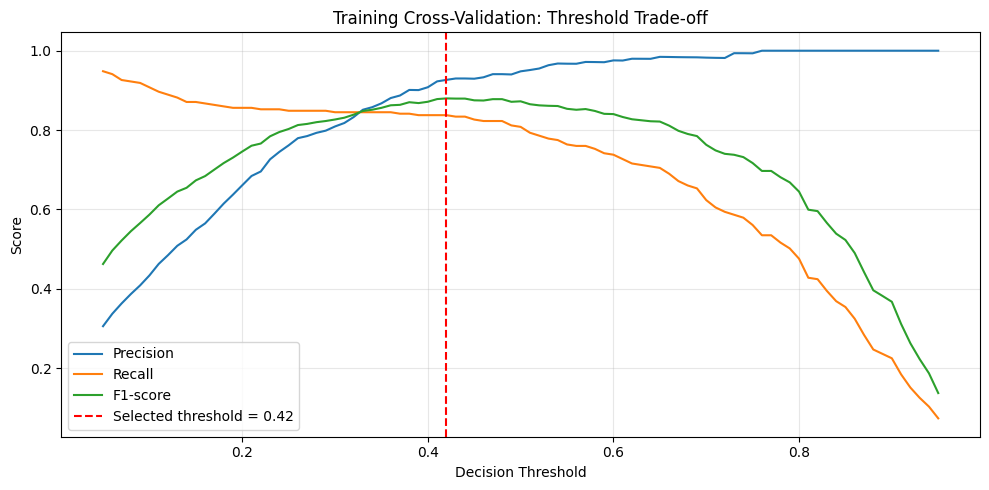

In [ ]:

# PHASE 8: DECISION THRESHOLD OPTIMIZATION
# Select the best threshold using TRAINING data only

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Training data is already prepared in
# PHASE 8 PREPARATION.

print("Training records:", len(X_train_fixed))
print("Training failures:", int(y_train_fixed.sum()))

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Out-of-fold predicted probabilities
# No test data is used for threshold selection.
oof_prob = cross_val_predict(
    rf_pipeline,
    X_train_fixed,
    y_train_fixed,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Evaluate different decision thresholds
thresholds = np.arange(0.05, 0.951, 0.01)

rows = []

for threshold in thresholds:

    predictions = (oof_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train_fixed,
        predictions,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train_fixed, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train_fixed, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train_fixed, predictions, zero_division=0
        ),
        "False alarms": fp,
        "Missed failures": fn
    })

threshold_df = pd.DataFrame(rows)

# Choose threshold with highest cross-validated F1
best_row = threshold_df.loc[
    threshold_df["F1-score"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("\nBEST THRESHOLD (TRAINING CV ONLY)")
print(f"Threshold: {best_threshold:.2f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"F1-score: {best_row['F1-score']:.4f}")

# Visualize threshold trade-offs
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    label="F1-score"
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Training Cross-Validation: Threshold Trade-off")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# PHASE 8B: FINAL TEST-SET THRESHOLD COMPARISON

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use the fitted Random Forest
# on the original held-out test data.

test_prob = rf_pipeline.predict_proba(
    X_test_fixed
)[:, 1]

comparison = []

for name, threshold in [
    ("Default threshold", 0.50),
    ("CV-selected threshold", best_threshold)
]:

    predictions = (
        test_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_ml,
        predictions,
        labels=[0, 1]
    ).ravel()

    comparison.append({
        "Threshold type": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test_ml, predictions
        ),
        "Precision": precision_score(
            y_test_ml, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_ml, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test_ml, predictions, zero_division=0
        ),
        "Detected failures": tp,
        "Missed failures": fn,
        "False alarms": fp
    })

comparison_df = pd.DataFrame(comparison)

print("FINAL TEST-SET THRESHOLD COMPARISON")
display(comparison_df.round(4))

print("\nFINAL INTERPRETATION")

default_f1 = comparison_df.iloc[0]["F1-score"]
optimized_f1 = comparison_df.iloc[1]["F1-score"]

if optimized_f1 > default_f1:
    print("CV-selected threshold improved test F1-score.")
elif optimized_f1 < default_f1:
    print("Default threshold achieved higher test F1-score.")
else:
    print("Both thresholds achieved the same test F1-score.")

print(
    "Threshold selection used training data only. "
    "The test set was used for final comparison."
)


FINAL TEST-SET THRESHOLD COMPARISON


,Threshold type,Threshold,Accuracy,Precision,Recall,F1-score,Detected failures,Missed failures,False alarms
0,Default threshold,0.50,0.9915,0.9474,0.7941,0.8640,54,14,3
1,CV-selected threshold,0.42,0.9920,0.9194,0.8382,0.8769,57,11,5



FINAL INTERPRETATION
CV-selected threshold improved test F1-score.
Threshold selection used training data only. The test set was used for final comparison.


## PHASE 9: MODEL RELIABILITY AND DATA LEAKAGE AUDIT

### Objective
To verify the reliability of the machine failure prediction model by checking training–testing separation, feature consistency, target leakage, and preprocessing procedures.

This audit helps establish whether the reported model performance can be trusted on unseen data.

In [ ]:

# PHASE 9A: MODEL RELIABILITY AND DATA LEAKAGE AUDIT

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

print("=" * 55)
print("PHASE 9A: MODEL RELIABILITY AUDIT")
print("=" * 55)

# 1. Training and testing separation
train_ids = X_train_fixed.index
test_ids = X_test_fixed.index

overlap = train_ids.intersection(test_ids)

print("\n1. TRAIN-TEST SEPARATION")
print("Training records:", len(train_ids))
print("Testing records:", len(test_ids))
print("Overlapping row indices:", len(overlap))

assert len(overlap) == 0, "ERROR: Train/test overlap detected!"

# 2. Feature schema consistency
print("\n2. FEATURE CONSISTENCY")

expected_features = rf_pipeline.feature_names_in_.tolist()

print("Expected features:", expected_features)
print("Training features:", X_train_fixed.columns.tolist())
print("Testing features:", X_test_fixed.columns.tolist())

assert X_train_fixed.columns.tolist() == expected_features
assert X_test_fixed.columns.tolist() == expected_features

print("Feature schemas match.")

# 3. Missing values and target leakage
print("\n3. MISSING VALUES AND TARGET LEAKAGE")

print("Missing training values:",
      X_train_fixed.isna().sum().sum())

print("Missing testing values:",
      X_test_fixed.isna().sum().sum())

target_col = "Machine failure"

assert target_col not in X_train_fixed.columns
assert target_col not in X_test_fixed.columns

print("Target column is not present in model inputs.")

# 4. Verify target alignment
print("\n4. TARGET ALIGNMENT")

assert X_train_fixed.index.equals(y_train_fixed.index)
assert X_test_fixed.index.equals(y_test.index)

print("Training and testing targets are index-aligned.")

# 5. Reconfirm final model performance
print("\n5. FINAL RANDOM FOREST PERFORMANCE")

audit_predictions = rf_pipeline.predict(X_test_fixed)

print("Accuracy:",
      round(accuracy_score(y_test, audit_predictions), 4))
print("Precision:",
      round(precision_score(y_test, audit_predictions), 4))
print("Recall:",
      round(recall_score(y_test, audit_predictions), 4))
print("F1-score:",
      round(f1_score(y_test, audit_predictions), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, audit_predictions))

# 6. Inspect fitted pipeline
print("\n6. MODEL PIPELINE STRUCTURE")
print(rf_pipeline)

print("\nPHASE 9A CHECKS COMPLETED")


PHASE 9A: MODEL RELIABILITY AUDIT

1. TRAIN-TEST SEPARATION
Training records: 8000
Testing records: 2000
Overlapping row indices: 0

2. FEATURE CONSISTENCY
Expected features: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Temperature difference', 'Mechanical power', 'Wear-load interaction', 'Type']
Training features: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Temperature difference', 'Mechanical power', 'Wear-load interaction', 'Type']
Testing features: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Temperature difference', 'Mechanical power', 'Wear-load interaction', 'Type']
Feature schemas match.

3. MISSING VALUES AND TARGET LEAKAGE
Missing training values: 0
Missing testing values: 0
Target column is not present in model inputs.

4. TARGET ALIGNMENT
Training and testing targets are index-aligned.

5. FINAL RANDOM FOREST PERFORMANCE
Accuracy: 0.9915
Precision: 

In [ ]:

# PHASE 9E: FINAL FEATURE AND DATA LEAKAGE VERIFICATION

import numpy as np
import pandas as pd

feature_cols = rf_pipeline.feature_names_in_.tolist()

# Verify feature schemas
assert X_train_fixed.columns.tolist() == feature_cols
assert X_test_fixed.columns.tolist() == feature_cols

# Verify dataset dimensions
assert X_train_fixed.shape == (8000, 9)
assert X_test_fixed.shape == (2000, 9)

# Verify training/test separation
assert X_train_fixed.index.intersection(
    X_test_fixed.index
).empty

# Verify target alignment
assert X_train_fixed.index.equals(y_train_fixed.index)
assert X_test_fixed.index.equals(y_test_ml.index)

# Verify target is excluded from predictors
assert "Machine failure" not in feature_cols

# Verify no missing predictor values
assert not X_train_fixed.isna().any().any()
assert not X_test_fixed.isna().any().any()

# Verify engineered features use correct formulas
for features in [X_train_fixed, X_test_fixed]:

    expected_temp_diff = (
        features["Process temperature"]
        - features["Air temperature"]
    )

    expected_power = (
        features["Torque"]
        * features["Rotational speed"]
        * (2 * np.pi / 60)
    )

    expected_wear_load = (
        features["Tool wear"] * features["Torque"]
    )

    assert np.allclose(
        features["Temperature difference"],
        expected_temp_diff
    )

    assert np.allclose(
        features["Mechanical power"],
        expected_power
    )

    assert np.allclose(
        features["Wear-load interaction"],
        expected_wear_load
    )

print("PHASE 9E: FINAL VERIFICATION")
print("Training shape:", X_train_fixed.shape)
print("Testing shape:", X_test_fixed.shape)
print("Feature schema: PASSED")
print("Train/test separation: PASSED")
print("Target alignment: PASSED")
print("Missing values: PASSED")
print("Engineered feature formulas: PASSED")
print("\nALL FINAL FEATURE CHECKS PASSED!")


PHASE 9E: FINAL VERIFICATION
Training shape: (8000, 9)
Testing shape: (2000, 9)
Feature schema: PASSED
Train/test separation: PASSED
Target alignment: PASSED
Missing values: PASSED
Engineered feature formulas: PASSED

ALL FINAL FEATURE CHECKS PASSED!


# PHASE 10: FINAL MODEL INTERPRETATION AND CONCLUSIONS

## 10.1 Project Objective

The objective of this project is to predict industrial machine failures using machine operating conditions such as rotational speed, torque, tool wear, and temperature. The project explores how machine learning can support preventive maintenance by identifying potential failures.

## 10.2 Final Model Performance

The project evaluated three classification approaches: Dummy Baseline, Logistic Regression, and Random Forest.

Random Forest was selected as the final model. Its performance was evaluated on 2,000 unseen test observations.

The final model uses a decision threshold of **0.42**, selected through five-fold stratified cross-validation on the training data.

| Evaluation Metric | Final Result |
|---|---|
| Accuracy | 99.20% |
| Precision | 91.94% |
| Recall | 83.82% |
| F1-score | 87.69% |
| Correctly detected failures | 57 |
| Missed failures | 11 |
| False alarms | 5 |

Because machine failures are relatively rare, accuracy alone is insufficient to evaluate model performance. Precision, recall, and F1-score provide a more meaningful assessment.

## 10.3 Confusion Matrix Interpretation

The final Random Forest model produced the following results:

- True Negatives (TN): 1,927
- False Positives (FP): 5
- False Negatives (FN): 11
- True Positives (TP): 57

The model correctly identified approximately 84% of actual machine failures.

However, 11 failures were not detected, demonstrating that the model still has limitations.

## 10.4 Feature Importance Analysis

Random Forest feature-importance analysis identified the following important predictors:

1. Rotational speed
2. Torque
3. Mechanical power
4. Tool wear
5. Wear-load interaction

These results suggest that mechanical operating conditions are important for predicting machine failures.

However, feature importance represents predictive contribution and does not establish a causal relationship.

## 10.5 Decision Threshold Optimization

The default classification threshold of 0.50 was compared with the optimized threshold of 0.42.

| Metric | Default (0.50) | Optimized (0.42) |
|---|---:|---:|
| Accuracy | 99.15% | 99.20% |
| Precision | 94.74% | 91.94% |
| Recall | 79.41% | 83.82% |
| F1-score | 86.40% | 87.69% |
| Detected failures | 54 | 57 |
| Missed failures | 14 | 11 |
| False alarms | 3 | 5 |

The optimized threshold detected three additional failures and reduced missed failures from 14 to 11.

Although false alarms increased from three to five, the optimized threshold improved recall and F1-score.

Therefore, **0.42 was selected as the final decision threshold** for this project.

## 10.6 Project Limitations

Despite strong results, the project has several limitations:

1. The dataset is synthetic and may not fully represent real industrial conditions.
2. Machine failure observations are relatively rare compared with normal observations.
3. The final model still misses 11 actual failures.
4. Model performance was evaluated using a single held-out test set.
5. Feature importance does not establish causation.
6. Further validation using real industrial data would be required before practical deployment.

## 10.7 Future Improvements

Future work could include:

1. Evaluating additional machine learning algorithms such as gradient boosting.
2. Exploring recall-oriented and cost-sensitive threshold selection.
3. Validating the model using real industrial sensor data.
4. Investigating techniques to reduce missed machine failures.
5. Developing a monitoring dashboard to visualize failure probabilities.

## 10.8 Final Conclusion

This project demonstrates the application of machine learning to industrial machine failure prediction.

The Random Forest classifier achieved strong predictive performance, with **99.20% accuracy, 83.82% recall, and an F1-score of 87.69%** using the optimized threshold of 0.42.

The project also demonstrates the importance of exploratory data analysis, feature engineering, class-imbalance-aware evaluation, model comparison, error analysis, and decision threshold optimization.

Although the model performs well on the synthetic dataset, additional validation would be necessary before deployment in real industrial environments.